# Part 2 - Brick Classifier Training

Fine-tuning ResNet-50 to identify the 50 most common PartID's. This notebook uses the images gathered by `01_build_subset.ipynb`.

2 Training phases
1. **Phase 1:** Only training the final output layer (50 class). The rest of the network is frozen.
2. **Phase 2:** Finetuning layer4 - The final block of the model

Notebook experiement: Do real photos make a difference in model performance or are renders good enough?

1. **Run A:** 400 Renders
2. **Run B:** As many real photos as possible (Up to 400) with the rest filled by renders.

## Settings

In [12]:
import os
from pathlib import Path

RUN_NAME = "B_mix"      # "A_renders" (baseline) or "B_mix" (change)
TRAIN_DATA = "mix"      # "renders" or "mix"
PER_CLASS = 400             # training images per partID
PHASE1_EPOCHS = 5           # output layer only
PHASE2_EPOCHS = 10          # output layer + layer4
LR_PHASE1 = 1e-3            # ~0.001
LR_PHASE2 = 1e-4            # ~0.0001
WEIGHT_DECAY = 1e-4         # Pulls weights towards 0
BATCH_SIZE = 64             # Number of Images (renders/real) per batch
NUM_WORKERS = min(4, os.cpu_count() or 2)
SEED = 539
SMOKE_TEST = False

REPO_URL = "https://github.com/divijsinghkohli/cs539-backprop-boys.git"
WORK = Path("/content")
DATA_DIR = WORK / "lego50"                      # images unzipped on the Colab VM
REPO_DIR = WORK / "repo"
DRIVE_DIR = Path("/content/drive/MyDrive/ece539-p2")
DATA_ZIP = DRIVE_DIR / "data" / "lego50.zip"    # from 01_build_subset
SPLITS_DIR = DRIVE_DIR / "results" / "splits"   # from 01_build_subset

## Setup

Mount the Drive, get classifier.py from Github, and images from the mounted Drive

In [13]:
import importlib, json, random, shutil, subprocess, sys
import numpy as np
import pandas as pd
import torch
from google.colab import drive

drive.mount("/content/drive")

if REPO_DIR.exists():
    subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only"], check=True)
else:
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(REPO_DIR)], check=True)
if str(REPO_DIR / "P2") not in sys.path:
    sys.path.insert(0, str(REPO_DIR / "P2"))
import classifier
importlib.reload(classifier)   # picks up changes after a git pull

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
print("Device:", torch.cuda.get_device_name(0) if use_amp else "Really should be using GPU here :) ")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

classes = classifier.load_classes(REPO_DIR / "P2" / "classes_50.csv") #Get Images

assert TRAIN_DATA in ("renders", "mix")
RUN = RUN_NAME + ("_smoke" if SMOKE_TEST else "")
n_classes_used = 5 if SMOKE_TEST else len(classes) #Smoke test uses smaller subset (5)
per_class = 50 if SMOKE_TEST else PER_CLASS
phase1_epochs, phase2_epochs = (1, 1) if SMOKE_TEST else (PHASE1_EPOCHS, PHASE2_EPOCHS)
total_epochs = phase1_epochs + phase2_epochs

RUN_DIR = DRIVE_DIR / "results" / "runs" / RUN     # small result files
CKPT_DIR = DRIVE_DIR / "checkpoints" / RUN         # model checkpoints
RUN_DIR.mkdir(parents=True, exist_ok=True)
CKPT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Run {RUN}: {n_classes_used} parts x {per_class} images, {phase1_epochs} + {phase2_epochs} epochs")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: Tesla T4
Run A_renders: 50 parts x 400 images, 5 + 10 epochs


## Load the images

Copies `lego50.zip` from Drive to the Colab VM and unzips it.

In [14]:
import zipfile

done_marker = DATA_DIR / ".unzipped"
if not done_marker.exists(): #Check if it has already been unzipped
    local_zip = WORK / "lego50.zip"
    shutil.copy(DATA_ZIP, local_zip)
    with zipfile.ZipFile(local_zip) as z:
        z.extractall(DATA_DIR)
    local_zip.unlink()
    done_marker.touch()
print("Images ready in: ", DATA_DIR)

def read_split(name):
    return pd.read_csv(SPLITS_DIR / f"{name}.csv", dtype={"path": str, "dataset_folder": str, "part_id": str})

train_all, dev_all = read_split("train"), read_split("dev")

#Make sure classes from 01 match classes_50.csv
folder_to_idx = dict(zip(classes.dataset_folder, classes.class_idx))
for df in (train_all, dev_all):
    assert (df.dataset_folder.map(folder_to_idx) == df.class_idx).all(), (
        "Split files do not match classes_50.csv. Re-run 01_build_subset.ipynb.")
assert (DATA_DIR / train_all.path.iloc[0]).exists(), "Image files missing from the unzipped data."
print(f"train.csv: {len(train_all):,} images | dev.csv: {len(dev_all):,} real photos") #Should be a (70/15/15) split.

Images ready in:  /content/lego50
train.csv: 111,463 images | dev.csv: 1,564 real photos


## Choose the training images

Choose the training images based on which run. In run A only use renders `renders` and run B uses `mixed`.

In [15]:
rng = np.random.default_rng(SEED)
used = classes.class_idx[:n_classes_used].tolist() #either all 50 or 5 (if smoke test)

chosen = []
for k in used:
    rows = train_all[train_all.class_idx == k]
    photos, renders = rows[rows.source == "photo"], rows[rows.source == "render"]
    n_photo = min(len(photos), per_class) if TRAIN_DATA == "mix" else 0 #if Run A then there should be 0 real photos
    n_render = per_class - n_photo #Backfill with renders
    assert len(renders) >= n_render, f"Class {k} has only {len(renders)} renders; {n_render} needed."
    chosen.append(photos.iloc[rng.permutation(len(photos))[:n_photo]])
    chosen.append(renders.iloc[rng.permutation(len(renders))[:n_render]])

train_sel = pd.concat(chosen, ignore_index=True)
dev_sel = dev_all[dev_all.class_idx.isin(used)].reset_index(drop=True)
train_sel.to_csv(RUN_DIR / "train_selected.csv", index=False)

real_share = (train_sel.source == "photo").mean()
print(f"Training images: {len(train_sel):,} ({real_share:.0%} real photos) | dev photos: {len(dev_sel):,}")
#This config will let us compare run A and run B based on the settings used.
config = {
    "RUN": RUN, "TRAIN_DATA": TRAIN_DATA, "PER_CLASS": per_class, "n_classes": n_classes_used,
    "PHASE1_EPOCHS": phase1_epochs, "PHASE2_EPOCHS": phase2_epochs, "LR_PHASE1": LR_PHASE1, "LR_PHASE2": LR_PHASE2,
    "WEIGHT_DECAY": WEIGHT_DECAY, "BATCH_SIZE": BATCH_SIZE, "SEED": SEED, "SMOKE_TEST": SMOKE_TEST,
    "optimizer": "AdamW", "phase2_schedule": "cosine", "loss": "cross-entropy", "mixed_precision": use_amp,
    "weights": "ResNet50 IMAGENET1K_V2", "n_train_images": len(train_sel), "n_train_real_photos": int((train_sel.source == "photo").sum()),
    "real_share": round(float(real_share), 4), "n_dev_photos": len(dev_sel),
    "device": torch.cuda.get_device_name(0) if use_amp else "cpu", "torch": str(torch.__version__),
}
(RUN_DIR / "config.json").write_text(json.dumps(config, indent=2))

Training images: 20,000 (0% real photos) | dev photos: 1,564


563

## Data loaders

Images are passed through the data augmentation (From classifier.py) or straight through (for eval)

In [16]:
from PIL import Image
from torch.utils.data import DataLoader, Dataset

class BrickDataset(Dataset):
    def __init__(self, df, transform):
        self.paths = [DATA_DIR / p for p in df.path]
        self.labels = df.class_idx.tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        with Image.open(self.paths[i]) as img:
            x = self.transform(img.convert("RGB")) #converrt images to RGB. Actual colors are NOT handled here.
        return x, self.labels[i]

train_loader = DataLoader(BrickDataset(train_sel, classifier.train_transforms()), batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=use_amp, generator=torch.Generator().manual_seed(SEED))
dev_loader = DataLoader(BrickDataset(dev_sel, classifier.eval_transforms()), batch_size=BATCH_SIZE * 2, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=use_amp)
print(f"{len(train_loader)} training batches, {len(dev_loader)} dev batches per epoch")

313 training batches, 13 dev batches per epoch


## Model

ResNet50 with ImageNet weights and a new 50-class output layer (50 PartID's). Records how much of the model is learning for each phase (1 or 2).

In [17]:
model = classifier.build_model(num_classes=len(classes)).to(device)

params = {}
for phase in (1, 2):
    trainable, frozen = classifier.set_trainable(model, phase)
    params[f"phase{phase}"] = {"trainable_layers": ["fc"] if phase == 1 else ["layer4", "fc"],
                               "trainable_params": trainable, "frozen_params": frozen}
(RUN_DIR / "params.json").write_text(json.dumps(params, indent=2))
pd.DataFrame(params).T

,trainable_layers,trainable_params,frozen_params
phase1,[fc],102450,23508032
phase2,"[layer4, fc]",15067186,8543296


## Training functions

* `make_optimizer`: sets which layers learn for a phase and creates an Adam Optimizer
* `run_epoch`: Runs each epoch through the model
* `save_checkpoint`: writes everything needed to resume (`last.pt`); written to a temporary file first so a disconnect mid-save cannot corrupt it. (Saved in Drive)

In [18]:
import time
import torch.nn.functional as F
from tqdm.auto import tqdm

def phase_of(epoch):
    if epoch <= phase1_epochs:
        return 1
    else:
        return 2

def make_optimizer(phase):
    classifier.set_trainable(model, phase) #Freezes/Unfreezes proper parts of the model based on phase
    trainable = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(trainable, lr=LR_PHASE1 if phase == 1 else LR_PHASE2, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=phase2_epochs) if phase == 2 else None
    return opt, sched

def run_epoch(loader, opt=None):
    training = opt is not None
    if not training:
        model.eval()
    total_loss, correct, seen = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in tqdm(loader, desc="train" if training else "dev", leave=False):
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                scores = model(x)
                loss = F.cross_entropy(scores, y)
            if training:
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(opt) #Update weights
                scaler.update()
            total_loss += loss.item() * len(y)
            correct += (scores.argmax(dim=1) == y).sum().item()
            seen += len(y)
    return total_loss / seen, correct / seen

def atomic_save(obj, path):
    tmp = path.with_name(path.name + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)

def save_checkpoint(epoch):
    atomic_save({"model_state": model.state_dict(), "optimizer_state": opt.state_dict(),
                 "scheduler_state": sched.state_dict() if sched else None, "scaler_state": scaler.state_dict(),
                 "epoch": epoch, "phase": phase_of(epoch), "best": best, "config": config}, CKPT_DIR / "last.pt")

## Resume or start

Use the saved checkpoints or begin training

In [19]:
LOG = RUN_DIR / "log.csv"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
best = {"dev_acc": -1.0, "epoch": 0}
start_epoch, opt, sched, opt_phase = 1, None, None, None

last = CKPT_DIR / "last.pt"
if last.exists():
    ck = torch.load(last, map_location=device, weights_only=True)
    must_match = ["TRAIN_DATA", "PER_CLASS", "n_classes", "PHASE1_EPOCHS", "PHASE2_EPOCHS",
                  "LR_PHASE1", "LR_PHASE2", "WEIGHT_DECAY", "BATCH_SIZE", "SEED"]
    changed = [k for k in must_match if ck["config"][k] != config[k]]
    assert not changed, f"Settings differ from the saved run {RUN}: {changed}. Use a new RUN_NAME or restore the settings."
    model.load_state_dict(ck["model_state"])
    scaler.load_state_dict(ck["scaler_state"])
    best = ck["best"]
    start_epoch = ck["epoch"] + 1
    if start_epoch <= total_epochs:
        opt_phase = phase_of(start_epoch)
        opt, sched = make_optimizer(opt_phase)
        if opt_phase == ck["phase"]:   #same phase: continue the optimizer and schedule where they stopped
            opt.load_state_dict(ck["optimizer_state"])
            if sched:
                sched.load_state_dict(ck["scheduler_state"])
    if LOG.exists():
        log = pd.read_csv(LOG)
        log[log.epoch <= ck["epoch"]].to_csv(LOG, index=False)
    print(f"Resuming {RUN} at epoch {start_epoch} of {total_epochs} "
          f"(best dev accuracy so far {best['dev_acc']:.3f}, epoch {best['epoch']})")
else:
    if LOG.exists():
        LOG.unlink()   #log from a run whose checkpoint no longer exists
    print(f"Starting {RUN} from epoch 1 of {total_epochs}")

Starting A_renders from epoch 1 of 15


## Train

For each epoch

In [20]:
for epoch in range(start_epoch, total_epochs + 1):
    phase = phase_of(epoch)
    if opt_phase != phase:
        opt, sched = make_optimizer(phase)
        opt_phase = phase
    classifier.set_trainable(model, phase)   #also restores train mode after the previous dev pass

    t0 = time.time()
    if use_amp:
        torch.cuda.reset_peak_memory_stats()
    train_loss, train_acc = run_epoch(train_loader, opt)
    dev_loss, dev_acc = run_epoch(dev_loader)
    lr = opt.param_groups[0]["lr"]
    if sched:
        sched.step()
    seconds = time.time() - t0

    if dev_acc > best["dev_acc"]:
        best = {"dev_acc": dev_acc, "epoch": epoch}
        atomic_save({"model_state": model.state_dict(), "epoch": epoch, "dev_acc": dev_acc, "config": config},
                    CKPT_DIR / "best.pt")

    row = {"epoch": epoch, "phase": phase, "train_loss": train_loss, "train_acc": train_acc,
           "dev_loss": dev_loss, "dev_acc": dev_acc, "lr": lr, "seconds": round(seconds, 1)}
    pd.DataFrame([row]).to_csv(LOG, mode="a", header=not LOG.exists(), index=False)
    save_checkpoint(epoch)

    mem = f" | GPU memory peak {torch.cuda.max_memory_allocated() / 1e9:.1f} GB" if use_amp else ""
    print(f"epoch {epoch:2d}/{total_epochs} phase {phase} | train loss {train_loss:.3f} acc {train_acc:.3f} | "
          f"dev loss {dev_loss:.3f} acc {dev_acc:.3f}{' *best*' if best['epoch'] == epoch else ''} | {seconds:.0f}s{mem}")

print(f"\nBest dev accuracy: {best['dev_acc']:.3f} at epoch {best['epoch']}  ->  {CKPT_DIR / 'best.pt'}")

train:   0%|          | 0/313 [00:00<?, ?it/s]

dev:   0%|          | 0/13 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7990e5a65ee0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7990e5a65ee0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

epoch  1/15 phase 1 | train loss 2.552 acc 0.343 | dev loss 2.648 acc 0.198 *best* | 179s | GPU memory peak 0.9 GB


train:   0%|          | 0/313 [00:00<?, ?it/s]

dev:   0%|          | 0/13 [00:00<?, ?it/s]

... (56 outputs left out)

train:   0%|          | 0/313 [00:00<?, ?it/s]

dev:   0%|          | 0/13 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7990e5a65ee0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7990e5a65ee0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

epoch 15/15 phase 2 | train loss 0.458 acc 0.840 | dev loss 2.307 acc 0.485 | 200s | GPU memory peak 1.1 GB

Best dev accuracy: 0.496 at epoch 12  ->  /content/drive/MyDrive/ece539-p2/checkpoints/A_renders/best.pt


## Training curves

Train and dev accuracy and loss per epoch, with the switch from phase 1 to phase 2 marked. Saved as `curves.png`.

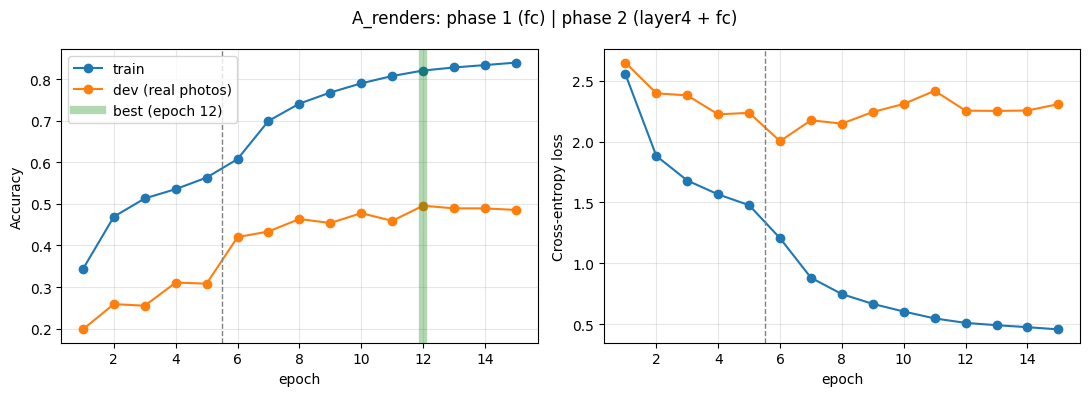

In [21]:
import matplotlib.pyplot as plt

log = pd.read_csv(LOG)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, label in ((axes[0], "acc", "Accuracy"), (axes[1], "loss", "Cross-entropy loss")):
    ax.plot(log.epoch, log[f"train_{metric}"], marker="o", label="train")
    ax.plot(log.epoch, log[f"dev_{metric}"], marker="o", label="dev (real photos)")
    ax.axvline(phase1_epochs + 0.5, color="gray", linestyle="--", linewidth=1)
    ax.set_xlabel("epoch")
    ax.set_ylabel(label)
    ax.grid(alpha=0.3)
axes[0].axvline(best["epoch"], color="green", alpha=0.3, linewidth=6, label=f"best (epoch {best['epoch']})")
axes[0].legend()
fig.suptitle(f"{RUN}: phase 1 (fc) | phase 2 (layer4 + fc)")
fig.tight_layout()
fig.savefig(RUN_DIR / "curves.png", dpi=150)
plt.show()

## Export the result files

Results at: `MyDrive/ece539-p2/results/runs/<run>/`

In [22]:
from google.colab import files

archive = shutil.make_archive(str(WORK / f"{RUN}_results"), "zip", RUN_DIR)
print("Results:", sorted(p.name for p in RUN_DIR.iterdir()))
files.download(archive)

Results: ['config.json', 'curves.png', 'log.csv', 'params.json', 'train_selected.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>